# Warsztat 2. Agent uczący się przejścia labiryntu

Podczas tego warsztatu zaimplementujecie agenta, który metodą prób i błędów uczy się
docierać do celu w labiryncie o wymiarach 5 × 5. Wykorzystacie do tego Q-learning,
czyli algorytm uczenia ze wzmocnieniem, w którym agent na podstawie nagród
otrzymywanych po kolejnych ruchach aktualizuje ocenę dostępnych działań. Po
zakończeniu treningu sprawdzicie, jak często dociera do celu i ile kroków potrzebuje
na przejście labiryntu, a następnie porównacie jego wyniki z wynikami agenta
poruszającego się losowo.

Środowisko labiryntu oraz funkcje służące do rysowania planszy i wykresów są już
przygotowane, dzięki czemu możecie skupić się na działaniu algorytmu i analizie
wyników. W sześciu obowiązkowych blokach `TODO` uzupełnicie kod odpowiedzialny za
wybór ruchu, uczenie i ocenę agenta, natomiast siódmy blok pozwoli wam wykonać
dodatkowy eksperyment. Odpowiedzi na pytania z sekcji „Do sprawozdania” oraz własne
obserwacje i wnioski zapisujcie w sprawozdaniu przygotowanym na podstawie
[szablonu sprawozdania](SZABLON_SPRAWOZDANIA.md).

Komórki uruchamiajcie w podanej kolejności, ponieważ kolejne etapy korzystają z
wcześniej zdefiniowanych funkcji i wyników. Jeśli pojawi się `NotImplementedError`,
uzupełnijcie wskazaną funkcję, uruchomcie ponownie jej komórkę i skorzystajcie ze
sprawdzeń pod zadaniem, zanim przejdziecie dalej.

Notebook korzysta z Pythona oraz bibliotek NumPy i Matplotlib, a pracować możecie w
Jupyterze lub Google Colab. W opisie planszy używamy współrzędnych
`(wiersz, kolumna)`, numerowanych od zera, przy czym numery wierszy rosną w dół.

In [1]:
from pathlib import Path
import csv
import json
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")

## Poznajcie środowisko i zapiszcie konfigurację

W tym środowisku stan agenta określa jego pozycja na planszy, a dostępne akcje
odpowiadają czterem kierunkom ruchu: w górę, w prawo, w dół i w lewo. Po każdej próbie
ruchu agent otrzymuje dokładnie jedną nagrodę zgodnie z poniższą tabelą. Wartości te
pozwalają premiować dotarcie do celu oraz uwzględniać koszt kolejnych kroków i
niedozwolonych ruchów.

| Zdarzenie | Nagroda | Skutek |
|---|---:|---|
| Wejście na cel | +10 | Epizod kończy się sukcesem. |
| Zwykły dozwolony ruch | −0,1 | Agent przechodzi na sąsiednie pole. |
| Ściana albo wyjście poza planszę | −1 | Agent pozostaje na dotychczasowym polu. |

Pojedynczą próbę przejścia labiryntu nazywamy epizodem. Epizod kończy się, gdy agent
dotrze do celu lub wykona 50 kroków. Każda próba ruchu zużywa jeden krok, również
wtedy, gdy ruch jest niedozwolony i pozycja agenta się nie zmienia.

Kod środowiska jest już przygotowany, więc możecie od razu obejrzeć planszę i
przykładowe przejście agenta losowego. Gotowa funkcja `shortest_steps()` wykorzystuje
przeszukiwanie wszerz (BFS), aby sprawdzić, czy cel jest osiągalny z danego pola, i
obliczyć długość najkrótszej drogi. BFS nie uczestniczy w wybieraniu ruchów agenta.

In [2]:
from collections import deque
from collections.abc import Sequence
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.colors import ListedColormap
from matplotlib.figure import Figure


Position = tuple[int, int]

SIZE = 5
WALLS = frozenset({(0, 1), (1, 1), (3, 1), (3, 3)})
GOAL = (4, 4)
GRID = np.zeros((SIZE, SIZE), dtype=int)
for _wall in WALLS:
    GRID[_wall] = 1

# Współrzędne mają postać (wiersz, kolumna); wiersz rośnie w dół.
ACTIONS = ((-1, 0), (0, 1), (1, 0), (0, -1))
ACTION_NAMES = ("góra", "prawo", "dół", "lewo")
ACTION_ARROWS = ("↑", "→", "↓", "←")

# Stała lista obejmuje każde wolne pole poza celem dokładnie raz.
TEST_STARTS = (
    (0, 0), (0, 2), (0, 3), (0, 4),
    (1, 0), (1, 2), (1, 3), (1, 4),
    (2, 0), (2, 1), (2, 2), (2, 3), (2, 4),
    (3, 0), (3, 2), (3, 4),
    (4, 0), (4, 1), (4, 2), (4, 3),
)

In [3]:
CONFIG = {
    "episodes": 300, "alpha": 0.1, "gamma": 0.95,
    "epsilon": 0.2, "max_steps": 50,
    "start_seed": 2026, "action_seed": 2027, "eval_seed": 2028,
}
print(json.dumps(CONFIG, ensure_ascii=False, indent=2))
print("Ściany:", sorted(WALLS), "| Cel:", GOAL)
print("Stałe starty testowe:", TEST_STARTS)

{
  "episodes": 300,
  "alpha": 0.1,
  "gamma": 0.95,
  "epsilon": 0.2,
  "max_steps": 50,
  "start_seed": 2026,
  "action_seed": 2027,
  "eval_seed": 2028
}
Ściany: [(0, 1), (1, 1), (3, 1), (3, 3)] | Cel: (4, 4)
Stałe starty testowe: ((0, 0), (0, 2), (0, 3), (0, 4), (1, 0), (1, 2), (1, 3), (1, 4), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (3, 0), (3, 2), (3, 4), (4, 0), (4, 1), (4, 2), (4, 3))


In [4]:
class MazeEnv:
    """Deterministyczne środowisko; limit kroków obsługuje run_episode."""

    def __init__(self) -> None:
        self.position: Position | None = None

    def reset(self, start: Position | None = None,
              rng: np.random.Generator | None = None) -> Position:
        """Ustaw start, a przy braku startu wylosuj wolne pole poza celem."""
        if start is None:
            if rng is None:
                raise ValueError("Losowy start wymaga generatora rng.")
            start = TEST_STARTS[int(rng.integers(len(TEST_STARTS)))]
        start = tuple(start)
        if start not in TEST_STARTS:
            raise ValueError("Start musi być wolnym polem innym niż cel.")
        self.position = start
        return self.position

    def step(self, action: int) -> tuple[Position, float, bool]:
        """Zwróć (nowy_stan, nagroda, osiągnięto_cel)."""
        if self.position is None:
            raise RuntimeError("Przed ruchem wywołaj reset().")
        if self.position == GOAL:
            raise RuntimeError("Epizod zakończył się. Wywołaj reset().")
        if action not in range(len(ACTIONS)):
            raise ValueError("Akcja musi być liczbą 0, 1, 2 lub 3.")
        dr, dc = ACTIONS[action]
        r, c = self.position
        candidate = (r + dr, c + dc)

        # Nagrody są rozłączne: każdy ruch otrzymuje dokładnie jedną.
        if not (0 <= candidate[0] < SIZE and 0 <= candidate[1] < SIZE):
            return self.position, -1.0, False
        if candidate in WALLS:
            return self.position, -1.0, False
        self.position = candidate
        if candidate == GOAL:
            return candidate, 10.0, True
        return candidate, -0.1, False


def shortest_steps(start: Position) -> int:
    """Liczba ruchów najkrótszej drogi wyznaczona BFS, bez udziału Q."""
    start = tuple(start)
    if start == GOAL:
        return 0
    if start not in TEST_STARTS:
        raise ValueError("Nieprawidłowy start.")
    queue = deque([(start, 0)])
    visited = {start}
    while queue:
        (r, c), distance = queue.popleft()
        for dr, dc in ACTIONS:
            candidate = (r + dr, c + dc)
            if not (0 <= candidate[0] < SIZE and 0 <= candidate[1] < SIZE):
                continue
            if candidate in WALLS or candidate in visited:
                continue
            if candidate == GOAL:
                return distance + 1
            visited.add(candidate)
            queue.append((candidate, distance + 1))
    raise ValueError("Cel nie jest osiągalny z tego startu.")

In [5]:
def plot_maze(path: Sequence[Position] | None = None, ax: Axes | None = None,
              title: str = "Labirynt 5 × 5") -> tuple[Figure, Axes]:
    """Gotowy rysunek planszy oraz opcjonalnie przebytej ścieżki."""
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(GRID, cmap=ListedColormap(["#f1f5f9", "#334155"]),
              vmin=0, vmax=1, interpolation="nearest")
    ax.scatter(GOAL[1], GOAL[0], s=650, marker="s", c="#a7f3d0", zorder=2)
    ax.text(GOAL[1], GOAL[0], "CEL", ha="center", va="center", color="#065f46")
    if path:
        rows, columns = zip(*path)
        ax.plot(columns, rows, "o-", color="#2563eb", markersize=4)
        ax.scatter(columns[0], rows[0], s=110, c="#f59e0b", zorder=5, label="Start")
        ax.legend(loc="upper left")
    ax.set_xticks(range(SIZE))
    ax.set_yticks(range(SIZE))
    ax.set_xticks(np.arange(-0.5, SIZE, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, SIZE, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_xlabel("Kolumna")
    ax.set_ylabel("Wiersz")
    ax.set_title(title)
    ax.set_aspect("equal")
    return ax.figure, ax


def plot_rewards(history: "Sequence[EpisodeResult]",
                 title: str = "Nagrody w kolejnych epizodach",
                 ax: Axes | None = None) -> tuple[Figure, Axes]:
    """Gotowy wykres nagród i średniej z pełnego okna 20 epizodów."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 3.5))
    rewards = np.asarray([episode.total_reward for episode in history])
    episodes = np.arange(1, len(rewards) + 1)
    ax.plot(episodes, rewards, color="#93c5fd", label="Nagroda epizodu")
    if len(rewards) >= 20:
        average = np.convolve(rewards, np.ones(20) / 20, mode="valid")
        ax.plot(episodes[19:], average, color="#1d4ed8", label="Średnia z 20 epizodów")
    ax.set(xlabel="Epizod", ylabel="Suma nagród", title=title)
    ax.grid(alpha=0.2)
    ax.legend()
    return ax.figure, ax


def show_table(headers: Sequence[str], rows: Sequence[Sequence[object]]) -> None:
    """Gotowe wyświetlanie tabeli bez Pandas."""
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join("---" for _ in headers) + " |"]
    lines.extend("| " + " | ".join(str(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

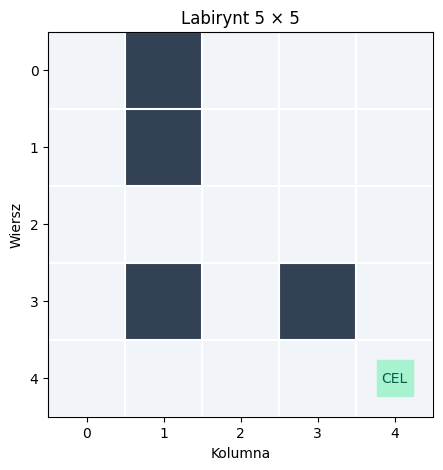

Agent losowy: sukces=True, kroki=31, nagroda=-4.7


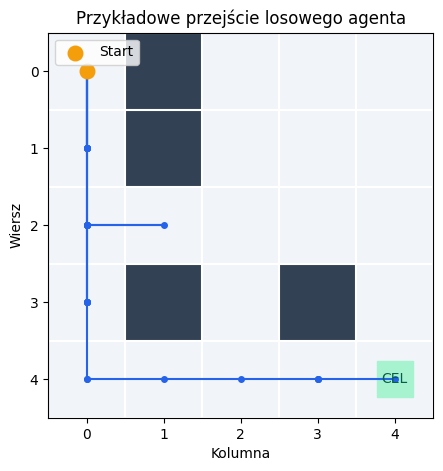

In [ ]:
assert len(TEST_STARTS) == 20
assert set(TEST_STARTS) == {
    (r, c) for r in range(SIZE) for c in range(SIZE)
    if (r, c) not in WALLS and (r, c) != GOAL
}
assert all(shortest_steps(start) > 0 for start in TEST_STARTS)
plot_maze()
plt.show()

demo_env = MazeEnv()
demo_rng = np.random.default_rng(2030)
demo_path = [demo_env.reset(TEST_STARTS[0])]
demo_return = 0.0
demo_success = False
for demo_step in range(1, CONFIG["max_steps"] + 1):
    action = int(demo_rng.integers(len(ACTIONS)))
    position, reward, demo_success = demo_env.step(action)
    demo_path.append(position)
    demo_return += reward
    if demo_success:
        break
print(f"Agent losowy: sukces={demo_success}, kroki={demo_step}, nagroda={demo_return:.1f}")
plot_maze(demo_path, title="Przykładowe przejście losowego agenta")
plt.show()

### Do sprawozdania. Konfiguracja i przewidywania

Skład zespołu podajcie w nagłówku sprawozdania, a odpowiedzi na poniższe pytania
zapiszcie w części „Konfiguracja i przewidywania”.

Wpiszcie imiona i nazwiska osób należących do waszego zespołu.

Zapiszcie parametry treningu oraz limit kroków przypadających na jeden epizod,
korzystając z konfiguracji wyświetlonej powyżej.

Opiszcie zachowanie agenta losowego, które zaobserwowaliście podczas przykładowego
przejścia. Jakich zmian w jego skuteczności i sposobie poruszania się oczekujecie po
wprowadzeniu uczenia?

Wyjaśnijcie, w jaki sposób sprawdziliście, że agent może dotrzeć do celu ze wszystkich
dozwolonych pól startowych.

## Tablica Q i wybór epsilon-zachłanny

### TODO 1. Utwórzcie tablicę wartości

Tablica Q przechowuje oszacowania wartości poszczególnych akcji w każdym stanie. W
naszym labiryncie dla każdej pozycji na planszy potrzebujemy czterech wartości, po
jednej dla każdego kierunku ruchu, dlatego tablica powinna mieć kształt `(5, 5, 4)`.

Zaimplementujcie funkcję `create_q()`, która tworzy taką tablicę NumPy z wartościami
zmiennoprzecinkowymi, początkowo równymi zero. Każde wywołanie funkcji powinno zwracać
nową, niezależną tablicę, aby zmiany wprowadzone podczas jednego treningu nie wpływały
na kolejny eksperyment.

Opis parametrów `shape` i `dtype` znajdziecie w
[dokumentacji `np.zeros()`](https://numpy.org/doc/2.3/reference/generated/numpy.zeros.html).

In [7]:
def create_q() -> np.ndarray:
    """Zwróć nową, zerową tablicę wartości par stan-akcja."""
    # TODO 1: utwórz tablicę i ją zwróć.
    raise NotImplementedError("TODO 1: utwórz zerową tablicę Q o kształcie (5, 5, 4).")

In [8]:
q_check = create_q()
assert isinstance(q_check, np.ndarray)
assert q_check.shape == (5, 5, 4), "Sprawdź liczbę pól i akcji."
assert np.issubdtype(q_check.dtype, np.floating), "Q musi przechowywać ułamki."
assert np.all(q_check == 0)
q_check[0, 0, 0] = 1
assert create_q()[0, 0, 0] == 0, "Każde wywołanie ma tworzyć nową tablicę."
print("TODO 1: kontrole zaliczone.")

NotImplementedError: TODO 1: utwórz zerową tablicę Q o kształcie (5, 5, 4).

### TODO 2. Zaimplementujcie wybór akcji

Zaimplementujcie funkcję `choose_action(q, state, epsilon, rng)`, która wybiera
jedną akcję dla bieżącej pozycji `state`. Funkcja ma zwracać indeks kierunku ruchu:
0 oznacza górę, 1 prawo, 2 dół, a 3 lewo.

`epsilon` jest liczbą od 0 do 1, która określa prawdopodobieństwo eksploracji,
czyli losowego wyboru ruchu. Przy `epsilon = 0.2` agent w około 20% decyzji losuje
jedną z czterech akcji, a w pozostałych 80% wybiera akcję o największej wartości
w `q[state]`. Losowe próby pozwalają mu odkrywać lepsze ruchy podczas treningu.

Jeśli kilka akcji ma tę samą największą wartość Q, rozstrzygnijcie remis przez
losowanie jednej z nich. Do wszystkich losowań używajcie przekazanego generatora
`rng`, a tablicę Q pozostawcie bez zmian.

Przy losowaniu przydadzą się opisy
[`rng.random()`](https://numpy.org/doc/2.3/reference/random/generated/numpy.random.Generator.random.html),
[`rng.integers()`](https://numpy.org/doc/2.3/reference/random/generated/numpy.random.Generator.integers.html)
i [`rng.choice()`](https://numpy.org/doc/2.3/reference/random/generated/numpy.random.Generator.choice.html).
Do wyszukiwania indeksów możecie wykorzystać
[`np.flatnonzero()`](https://numpy.org/doc/2.3/reference/generated/numpy.flatnonzero.html).

In [ ]:
def choose_action(q: np.ndarray, state: Position, epsilon: float,
                  rng: np.random.Generator) -> int:
    """Wybierz akcję epsilon-zachłannie, z losowym rozstrzyganiem remisów."""
    # TODO 2: eksploracja, wybór maksimum oraz losowanie przy remisach.
    raise NotImplementedError("TODO 2: uzupełnij wybór epsilon-zachłanny.")

In [ ]:
rng_check = np.random.default_rng(42)
q_check = create_q()
q_check[0, 0] = [0, 4, 1, -2]
assert {choose_action(q_check, (0, 0), 0.0, rng_check) for _ in range(40)} == {1}
assert {choose_action(q_check, (0, 0), 1.0, rng_check) for _ in range(200)} == {0, 1, 2, 3}
q_tie = create_q()
q_tie[0, 0] = [3, 1, 3, -1]
assert {choose_action(q_tie, (0, 0), 0.0, rng_check) for _ in range(200)} == {0, 2}
assert np.array_equal(q_tie[0, 0], [3, 1, 3, -1]), "Wybór akcji nie zmienia Q."
print("TODO 2: kontrole zaliczone.")

## Aktualizacja Q i trening

### TODO 3. Uzupełnijcie aktualizację Q-learning

W funkcji `update_q()` poprawicie ocenę wykonanej akcji na podstawie otrzymanej
nagrody i przewidywanych korzyści z kolejnych ruchów. Łącząc te informacje,
wyznaczacie wartość docelową, w stronę której powinna zmienić się obecna ocena Q.

Parametr $\gamma$ (`gamma`) określa znaczenie przyszłych nagród. Przy `gamma = 0`
liczy się tylko bieżąca nagroda, a przy `gamma = 0.95` dużą wagę mają również
korzyści z dalszych ruchów.

Następnie porównujecie wartość docelową z dotychczasową oceną Q i dodajecie do Q
część uzyskanej różnicy. Wielkością tej korekty steruje parametr $\alpha$ (`alpha`):
przy `alpha = 0.1` dodajecie 10% różnicy, więc nowa informacja stopniowo zmienia
wcześniejszą ocenę.

We wzorze $s$ oznacza stan przed ruchem, $a$ wybraną akcję, $r$ otrzymaną nagrodę,
a $s'$ stan po ruchu. Przyszłą wartość $V(s')$ przyjmijcie jako najlepszą ocenę
akcji w kolejnym stanie, czyli $\max_{a'}Q(s',a')$. Po osiągnięciu celu
(`terminated=True`) wynosi ona zero. Sam limit kroków nie zeruje przyszłej wartości.

Tak opisaną aktualizację zapisujemy jako:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[r + \gamma V(s') - Q(s,a)].$$

Zmieńcie tylko wskazaną parę stan-akcja bezpośrednio w przekazanej tablicy Q.
Funkcja nie musi niczego zwracać.

Do obliczenia wartości następnego stanu przyda się
[`np.max()`](https://numpy.org/doc/2.3/reference/generated/numpy.max.html).
Zasady odczytu i zmiany elementów tablicy opisuje
[dokumentacja indeksowania NumPy](https://numpy.org/doc/2.3/user/basics.indexing.html).

In [ ]:
def update_q(q: np.ndarray, state: Position, action: int, reward: float,
             next_state: Position, terminated: bool,
             alpha: float = CONFIG["alpha"], gamma: float = CONFIG["gamma"]) -> None:
    """Zmień jedną wartość Q na podstawie pojedynczego przejścia."""
    # TODO 3: przyszła wartość, wartość docelowa, aktualizacja wskazanej pary.
    raise NotImplementedError("TODO 3: uzupełnij aktualizację Q-learning.")

In [ ]:
q_check = create_q()
q_check[0, 0, 1] = 2
q_check[1, 0] = 8
update_q(q_check, (0, 0), 1, 1, (1, 0), False, alpha=0.1, gamma=0.5)
assert np.isclose(q_check[0, 0, 1], 2.3), "Sprawdź aktualizację przejścia bez celu."
assert np.all(q_check[1, 0] == 8), "Nie zmieniaj wartości innego stanu."

q_check[0, 0, 1] = 2
q_check[GOAL] = 1000  # Te wartości nie powinny wpływać na aktualizację końcową.
update_q(q_check, (0, 0), 1, 10, GOAL, True, alpha=0.1, gamma=0.95)
assert np.isclose(q_check[0, 0, 1], 2.8), "Po osiągnięciu celu przyszła wartość wynosi zero."
print("TODO 3: kontrole zaliczone.")

### TODO 4. Uzupełnijcie pętlę epizodu

W funkcji `run_episode()` uzupełnijcie pięć fragmentów oznaczonych `...`: górną
granicę pętli, wykonanie ruchu w środowisku, wywołanie `update_q()`, dodanie nagrody
do sumy oraz ustawienie nowego stanu przed kolejnym ruchem. Kroki numerujemy od 1,
a pętla powinna pozwalać na wykonanie `max_steps` ruchów, chyba że agent wcześniej
dotrze do celu. Przy aktualizacji Q przekażcie dane bieżącego przejścia oraz
parametry `alpha` i `gamma`. W tym miejscu `state` nadal oznacza pozycję przed
ruchem, a `next_state` pozycję po jego wykonaniu.

Szósty fragment znajduje się w funkcji `train()`, w wywołaniu `run_episode(...)`.
Przekażcie środowisko, bieżący start, generator `rng`, tablicę Q oraz parametry
`epsilon`, `alpha`, `gamma` i `max_steps`, a także włączcie uczenie przez
`learn=True`. Po uzupełnieniu obu funkcji uruchomcie sprawdzenia i trening poniżej.

Funkcja `train()` korzysta z waszych `create_q()`, `choose_action()` oraz
uzupełnionego `run_episode()`, aby przeprowadzić cały trening. Pola startowe dla
kolejnych epizodów są losowane jednorazowo przed rozpoczęciem uczenia i zapisywane w
`training_starts`. Zachowajcie tę listę, ponieważ w zadaniu dodatkowym wykorzystacie
ją do porównania różnych wartości epsilon przy tych samych startach. W podstawowym
eksperymencie pozostawcie parametry zapisane w `CONFIG`.

In [ ]:
@dataclass
class EpisodeResult:
    start: Position
    success: bool
    steps: int
    total_reward: float
    terminated: bool
    truncated: bool
    path: list[Position]
    actions: list[int]


def run_episode(env: MazeEnv, start: Position, rng: np.random.Generator,
                q: np.ndarray | None = None, epsilon: float = CONFIG["epsilon"],
                learn: bool = False, alpha: float = CONFIG["alpha"],
                gamma: float = CONFIG["gamma"],
                max_steps: int = CONFIG["max_steps"]) -> EpisodeResult:
    """Szkielet epizodu z pięcioma fragmentami do uzupełnienia w TODO 4."""
    if learn and q is None:
        raise ValueError("Uczenie wymaga tablicy Q.")
    state = env.reset(start)
    path, actions = [state], []
    total_reward = 0.0
    terminated = False
    # Wykonajcie maksymalnie max_steps ruchów, numerowanych od 1.
    for step in range(1, ...):  # FIXME
        action = (int(rng.integers(len(ACTIONS))) if q is None
                  else choose_action(q, state, epsilon, rng))
        # Wykonajcie ruch i odczytajcie wynik ze środowiska.
        next_state, reward, terminated = ...  # FIXME
        if learn:
            # Wywołajcie update_q dla tego przejścia z przekazanymi alpha i gamma.
            ...  # FIXME
        # Dodajcie nagrodę z bieżącego ruchu do wyniku epizodu.
        total_reward += ...  # FIXME
        actions.append(action)
        path.append(next_state)
        # Ustawcie stan, z którego agent wybierze kolejny ruch.
        state = ...  # FIXME
        if terminated:
            break
    return EpisodeResult(
        start=tuple(start), success=terminated, steps=step,
        total_reward=float(total_reward), terminated=terminated,
        truncated=not terminated, path=path, actions=actions,
    )


def sample_training_starts(episodes: int = CONFIG["episodes"],
                           seed: int = CONFIG["start_seed"]) -> list[Position]:
    """Osobny generator przygotowuje starty niezależnie od losowania akcji."""
    rng = np.random.default_rng(seed)
    return [TEST_STARTS[int(i)]
            for i in rng.integers(len(TEST_STARTS), size=episodes)]


def train(epsilon: float = CONFIG["epsilon"], episodes: int = CONFIG["episodes"],
          alpha: float = CONFIG["alpha"], gamma: float = CONFIG["gamma"],
          max_steps: int = CONFIG["max_steps"],
          starts: Sequence[Position] | None = None,
          action_seed: int = CONFIG["action_seed"]) -> tuple[np.ndarray, list[EpisodeResult]]:
    """Gotowy szkielet treningu korzystający z funkcji uczestników."""
    if starts is None or len(starts) != episodes:
        raise ValueError("Podaj wcześniej przygotowaną listę startów długości episodes.")
    q = create_q()
    rng = np.random.default_rng(action_seed)
    env = MazeEnv()
    history = []
    for start in starts:
        # Przekażcie dane epizodu i parametry treningu oraz włączcie uczenie.
        result = run_episode(...)
        history.append(result)
    return q, history

In [ ]:
# Cel w ostatnim dozwolonym kroku nadal oznacza sukces.
q_check = create_q()
q_check[4, 3, 1] = 1
ep_check = run_episode(MazeEnv(), (4, 3), np.random.default_rng(1),
                       q=q_check, epsilon=0, learn=True, alpha=1, max_steps=1)
assert ep_check.success and ep_check.terminated and not ep_check.truncated
assert ep_check.steps == 1 and np.isclose(q_check[4, 3, 1], 10)

# Po kroku bez celu przyszła wartość nadal liczy się mimo limitu.
q_check = create_q()
q_check[2, 0, 1] = 5
q_check[2, 1] = 4
ep_check = run_episode(MazeEnv(), (2, 0), np.random.default_rng(1),
                       q=q_check, epsilon=0, learn=True, alpha=1, gamma=0.95,
                       max_steps=1)
assert not ep_check.success and not ep_check.terminated and ep_check.truncated
assert np.isclose(q_check[2, 0, 1], 3.7), "Limit czasu nie zeruje przyszłego Q."

# Kolejny ruch powinien korzystać z nowego stanu, a wynik obejmować obie nagrody.
q_check = create_q()
q_check[0, 2, 2] = 1
q_check[1, 2, 1] = 1
ep_check = run_episode(MazeEnv(), (0, 2), np.random.default_rng(1),
                       q=q_check, epsilon=0, learn=False, max_steps=2)
assert ep_check.actions == [2, 1], "Wybierajcie kolejny ruch na podstawie nowego stanu."
assert ep_check.path == [(0, 2), (1, 2), (1, 3)]
assert np.isclose(ep_check.total_reward, -0.2), "Zsumujcie nagrody ze wszystkich ruchów."
print("TODO 4: kontrole zaliczone.")

In [ ]:
training_starts = sample_training_starts(CONFIG["episodes"], CONFIG["start_seed"])
q, history = train(
    epsilon=CONFIG["epsilon"], episodes=CONFIG["episodes"],
    alpha=CONFIG["alpha"], gamma=CONFIG["gamma"], max_steps=CONFIG["max_steps"],
    starts=training_starts, action_seed=CONFIG["action_seed"],
)
assert len(history) == 300
assert [episode.start for episode in history] == training_starts
plot_rewards(history)
plt.show()

### Do sprawozdania. Obserwacje podczas treningu

Odpowiedzi na poniższe pytania zapiszcie w części „Analiza” waszego sprawozdania,
odwołując się do wykresu nagród umieszczonego w części „Wyniki”.

Opiszcie, jak zmieniała się suma nagród w kolejnych epizodach treningu. Czy wzrastała
w każdym epizodzie i co na ten temat pokazuje wykres?

Wyjaśnijcie, dlaczego agent podczas treningu może wybrać gorszy ruch, nawet jeśli
wcześniej znalazł już korzystniejszą akcję w danym stanie.

Zastanówcie się, jak różne pola startowe i ich odległość od celu wpływają na sumę
nagród. Jak należy uwzględnić te różnice podczas interpretacji wykresu?

## Ocena gotowej strategii

### TODO 5. Ustawcie warunki testu

W tym etapie porównacie agenta losowego i wyuczonego na tej samej liście
`TEST_STARTS`, która zawiera 20 pozycji startowych. Wspólne starty pozwolą zestawić
ich wyniki dla tych samych prób przejścia labiryntu.

Aby ocenić strategię wypracowaną podczas treningu, ustawcie eksplorację wyuczonego
agenta na zero i wyłączcie aktualizowanie Q na czas testu. W tym celu uzupełnijcie
stałe `EPSILON_TEST` oraz `LEARN_DURING_TEST` w poniższej komórce. Gotowa funkcja
`evaluate()` wykorzystuje te ustawienia przy wykonywaniu prób.

Przez cały test korzystajcie z tej samej wyuczonej tablicy Q i nie uruchamiajcie
dodatkowego treningu pomiędzy próbami. Dzięki temu wszystkie wyniki będą dotyczyły
strategii uzyskanej na końcu wcześniejszego etapu.

In [ ]:
# TODO 5: wpisz warunki oceny zamrożonej strategii zamiast wielokropków.
EPSILON_TEST = ...
LEARN_DURING_TEST = ...
if EPSILON_TEST is Ellipsis or LEARN_DURING_TEST is Ellipsis:
    raise NotImplementedError("TODO 5: uzupełnij epsilon testowe i flagę uczenia.")


def evaluate(q: np.ndarray | None = None, starts: Sequence[Position] = TEST_STARTS,
             seed: int = CONFIG["eval_seed"],
             max_steps: int = CONFIG["max_steps"]) -> list[EpisodeResult]:
    """Gotowa ocena wykorzystująca warunki testu wybrane przez uczestników."""
    rng = np.random.default_rng(seed)
    env = MazeEnv()
    return [run_episode(env, start, rng, q=q, epsilon=EPSILON_TEST,
                        learn=LEARN_DURING_TEST, max_steps=max_steps)
            for start in starts]

In [ ]:
assert EPSILON_TEST == 0, "W teście wyłącz eksplorację."
assert LEARN_DURING_TEST is False, "W teście wyłącz aktualizowanie Q."
q_before_test = q.copy()
random_results = evaluate(seed=CONFIG["eval_seed"], max_steps=CONFIG["max_steps"])
learned_results = evaluate(q=q, seed=CONFIG["eval_seed"], max_steps=CONFIG["max_steps"])
assert np.array_equal(q, q_before_test), "Ocena zmieniła tablicę Q!"
assert len(random_results) == len(learned_results) == 20
assert [ep.start for ep in random_results] == [ep.start for ep in learned_results] == list(TEST_STARTS)
print("TODO 5: te same starty, ocena bez aktualizacji Q.")

### TODO 6. Obliczcie metryki

Zaimplementujcie funkcję `summarize(results)`, która podsumowuje listę wyników
epizodów i zwraca słownik z polami opisanymi w poniższej tabeli. Na jego podstawie
porównacie skuteczność obu agentów oraz liczbę kroków potrzebnych im do osiągnięcia
celu.

| Pole | Znaczenie |
|---|---|
| `episodes` | Podaje łączną liczbę przeprowadzonych prób. |
| `successes` | Podaje liczbę prób zakończonych dotarciem do celu. |
| `failures` | Podaje liczbę prób, w których agent nie dotarł do celu. |
| `success_rate` | Określa udział udanych prób wśród wszystkich prób jako liczbę od 0 do 1. |
| `mean_steps_success` | Podaje średnią liczbę kroków tylko dla udanych prób; jeśli takich prób nie było, ma wartość `None`. |

Obliczając skuteczność, podzielcie liczbę sukcesów przez liczbę wszystkich prób,
wliczając również niepowodzenia. Próba, w której agent wykonał 50 kroków bez
osiągnięcia celu, powinna zostać uwzględniona jako niepowodzenie.

Średnią liczbę kroków obliczcie wyłącznie dla prób zakończonych sukcesem. Jeśli agent
ani razu nie dotarł do celu, zapiszcie w tym polu `None`, ponieważ w takim przypadku
nie ma udanych prób, dla których można wyznaczyć średnią.

Sposób obliczania średniej opisuje
[dokumentacja `np.mean()`](https://numpy.org/doc/2.3/reference/generated/numpy.mean.html).

In [ ]:
def summarize(results: Sequence[EpisodeResult]) -> dict[str, int | float | None]:
    """Policz skuteczność wszystkich prób i średnią kroków w sukcesach."""
    # TODO 6: oblicz pięć wymaganych pól i zwróć słownik.
    raise NotImplementedError("TODO 6: policz metryki, zachowując niepowodzenia w ocenie skuteczności.")

In [ ]:
def metric_case(success: bool, steps: int) -> EpisodeResult:
    return EpisodeResult((0, 0), success, steps, 0.0,
                         success, not success, [], [])

metrics_check = summarize([metric_case(True, 6), metric_case(False, 50), metric_case(True, 10)])
assert metrics_check["episodes"] == 3
assert metrics_check["successes"] == 2 and metrics_check["failures"] == 1
assert np.isclose(metrics_check["success_rate"], 2 / 3)
assert np.isclose(metrics_check["mean_steps_success"], 8)
metrics_check = summarize([metric_case(False, 50), metric_case(False, 50)])
assert metrics_check["success_rate"] == 0
assert metrics_check["mean_steps_success"] is None
print("TODO 6: kontrole zaliczone.")

In [ ]:
tests = {"Losowy": random_results, "Wyuczony": learned_results}
summaries = {name: summarize(results) for name, results in tests.items()}
show_table(
    ["Agent", "Sukcesy / próby", "Skuteczność", "Niepowodzenia", "Śr. kroków w sukcesach"],
    [[name, f'{m["successes"]}/{m["episodes"]}', f'{100*m["success_rate"]:.1f}%',
      m["failures"], "brak" if m["mean_steps_success"] is None else f'{m["mean_steps_success"]:.2f}']
     for name, m in summaries.items()],
)

paired_rows = []
for trial, (random_ep, learned_ep) in enumerate(zip(random_results, learned_results), 1):
    paired_rows.append([trial, random_ep.start, random_ep.success, random_ep.steps,
                        learned_ep.success, learned_ep.steps])
show_table(["Próba", "Start", "Losowy: sukces", "Losowy: kroki", "Q: sukces", "Q: kroki"], paired_rows)

## Ścieżka, interpretacja i sprawozdanie

W tej części porównacie ścieżki obu agentów dla tego samego pola startowego. Poniższa
komórka wykorzystuje przejścia zapisane podczas testu, dzięki czemu rysunki
przedstawiają dokładnie te próby, które zostały uwzględnione w tabeli wyników.
Zmieniając `example_index`, możecie obejrzeć przejścia z innego wspólnego startu bez
ponownego wykonywania testu.

Po niedozwolonym ruchu agent pozostaje na tym samym polu, dlatego kolejne punkty jego
ścieżki nakładają się na rysunku. Pamiętajcie o tym podczas interpretacji wykresu,
ponieważ taka próba ruchu nadal jest wliczana do liczby wykonanych kroków.

In [ ]:
example_index = 0
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, name, episode in zip(axes, ("Losowy", "Wyuczony"),
                            (random_results[example_index], learned_results[example_index])):
    plot_maze(episode.path, ax=ax,
              title=f"{name}: {episode.steps} kroków, sukces={episode.success}")
fig.tight_layout()
plt.show()

### Do sprawozdania. Wyniki i wnioski

Metryki zapiszcie w części „Wyniki” sprawozdania, a ich interpretację i odpowiedzi na
pytania wyjaśniające zamieśćcie w części „Analiza”.

Podajcie skuteczność agenta losowego oraz liczbę jego sukcesów i wszystkich
przeprowadzonych prób.

Podajcie skuteczność wyuczonego agenta oraz liczbę jego sukcesów i wszystkich
przeprowadzonych prób.

Dla każdego z agentów podajcie średnią liczbę kroków w próbach zakończonych sukcesem
oraz liczbę udanych prób, na podstawie których obliczyliście tę średnią.

Porównajcie wyniki obu agentów i opiszcie, co na temat ich zachowania pokazują
przykładowe ścieżki przez labirynt.

Wyjaśnijcie, jak pozostawienie aktywnej eksploracji podczas testu wpłynęłoby na
interpretację wyników i dlaczego taki test nie mierzyłby samej wyuczonej strategii.

Opiszcie, w jaki sposób sprawdziliście, że podczas testu tablica Q pozostała
niezmieniona.

Wyjaśnijcie, dlaczego uzyskane wyniki odnoszą się do używanej planszy i nie
wystarczają do oceny działania agenta w dowolnym labiryncie.

### Zapis danych do sprawozdania

Po uzupełnieniu zadań uruchomcie poniższą komórkę, która zapisze wasze wyniki w
katalogu `results`. Znajdą się tam tablica Q, konfiguracja eksperymentu wraz z polami
startowymi, tabele wyników oraz historia nagród i wykres z treningu. Dzięki tym plikom
będziecie mogli wrócić do danych wykorzystanych w sprawozdaniu.

Przygotujcie sprawozdanie na podstawie uzyskanych tabel i wykresu, zapisując w nim
odpowiedzi na pytania z sekcji „Do sprawozdania” oraz własne wnioski z eksperymentu.
Skorzystajcie z [szablonu sprawozdania](SZABLON_SPRAWOZDANIA.md), który porządkuje
konfigurację, wyniki i analizę. Zapiszcie również uzupełniony notebook wraz z wynikami
komórek, aby można było prześledzić przebieg waszej pracy.

In [ ]:
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)
np.save(output_dir / "q_table.npy", q)
with (output_dir / "config.json").open("w", encoding="utf-8") as handle:
    json.dump({"parameters": CONFIG, "walls": sorted(WALLS), "goal": GOAL,
               "training_starts": training_starts, "test_starts": TEST_STARTS},
              handle, ensure_ascii=False, indent=2)

with (output_dir / "test_trials.csv").open("w", encoding="utf-8", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["agent", "trial", "start_row", "start_col", "success", "steps", "steps_if_success"])
    for name, results in tests.items():
        for trial, episode in enumerate(results, 1):
            writer.writerow([name, trial, *episode.start, episode.success, episode.steps,
                             episode.steps if episode.success else ""])

with (output_dir / "training_rewards.csv").open("w", encoding="utf-8", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["episode", "total_reward", "success", "steps"])
    writer.writerows([i, ep.total_reward, ep.success, ep.steps] for i, ep in enumerate(history, 1))

with (output_dir / "summary.csv").open("w", encoding="utf-8", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["agent", "episodes", "successes", "failures", "success_rate", "mean_steps_success"])
    for name, m in summaries.items():
        writer.writerow([name, m["episodes"], m["successes"], m["failures"],
                         m["success_rate"], m["mean_steps_success"]])
figure, _ = plot_rewards(history)
figure.savefig(output_dir / "rewards.png", dpi=150, bbox_inches="tight")
plt.close(figure)
print("Zapisano Q, konfigurację, tabele CSV i wykres w:", output_dir.resolve())

### Przygotowanie materiałów i prezentacji

Przed przesłaniem materiałów na Teams sprawdźcie, czy dołączacie kod, parametry
eksperymentu, wykres nagród, pełną tabelę testową oraz sprawozdanie z autorami i
własnymi wnioskami. Dołączcie też tablicę Q lub kod i konfigurację pozwalające ją
odtworzyć. W tabeli pozostawcie wszystkie przeprowadzone próby, również te zakończone
niepowodzeniem, ponieważ są potrzebne do oceny skuteczności agenta.

Na prezentację zespołu przewidziano od 5 do 6 minut. W tym czasie pokażcie przykładowe
przejście przez labirynt i omówcie porównanie wyników z agentem losowym. Wyjaśnijcie
również, jaką rolę pełniła eksploracja podczas treningu waszego agenta.

## Zakres dodatkowy. Porównanie epsilon 0,05 i 0,3

### TODO 7. Zaprojektujcie rzetelne porównanie

W zadaniu dodatkowym sprawdzicie, jak zmiana wartości epsilon wpływa na przebieg
uczenia i końcowe wyniki agenta. Zaimplementujcie funkcję `run_epsilon_comparison()`,
która dla każdej z wartości 0,05 i 0,3 przeprowadzi osobny trening rozpoczynający się
od nowej tablicy Q wypełnionej zerami.

W obu treningach zachowajcie 300 epizodów, pozostałe parametry eksperymentu oraz tę
samą listę `training_starts`. Każdą uzyskaną strategię oceńcie na wspólnej liście
`TEST_STARTS`, przy wyłączonym uczeniu i eksploracji. Zachowajcie również
dotychczasową planszę i zasady środowiska, aby porównanie dotyczyło wpływu samej
wartości epsilon.

Funkcja powinna zwracać trzy słowniki, których kluczami są wartości epsilon, a
zawartością odpowiednio tablice Q, historie treningu i wyniki testów. Podstawowa
tablica `q` i historia `history` powinny pozostać niezmienione, aby nadal opisywały
eksperyment obowiązkowy.

Jeśli realizujecie wyłącznie zakres obowiązkowy, możecie pominąć ten blok i dalszą
część notebooka. Po uzupełnieniu funkcji ustawcie `RUN_EXTRA = True`, aby uruchomić
porównanie oraz wyświetlić jego wyniki.

In [ ]:
RUN_EXTRA = False


def run_epsilon_comparison(epsilons: Sequence[float] = (0.05, 0.3)) -> tuple[
    dict[float, np.ndarray],
    dict[float, list[EpisodeResult]],
    dict[float, list[EpisodeResult]],
]:
    """Zwróć (extra_qs, extra_histories, extra_tests), słowniki według epsilon."""
    # TODO 7: osobne treningi od zera, wspólne starty, ocena gotowych strategii.
    raise NotImplementedError("TODO 7, dodatkowe: porównaj epsilon 0.05 i 0.3.")

In [ ]:
if RUN_EXTRA:
    q_before_extra = q.copy()
    extra_qs, extra_histories, extra_tests = run_epsilon_comparison()
    assert set(extra_qs) == set(extra_histories) == set(extra_tests) == {0.05, 0.3}
    assert np.array_equal(q, q_before_extra), "Nie zmieniaj Q podstawowego eksperymentu."
    extra_summaries = {}
    for epsilon in (0.05, 0.3):
        assert len(extra_histories[epsilon]) == 300
        assert [ep.start for ep in extra_histories[epsilon]] == training_starts
        assert [ep.start for ep in extra_tests[epsilon]] == list(TEST_STARTS)
        extra_summaries[epsilon] = summarize(extra_tests[epsilon])
        plot_rewards(extra_histories[epsilon], title=f"Trening, epsilon = {epsilon}")
        plt.show()

    comparison = {0.2: summaries["Wyuczony"], **extra_summaries}
    show_table(["Epsilon treningowe", "Sukcesy / próby", "Skuteczność", "Śr. kroków w sukcesach"],
               [[epsilon, f'{m["successes"]}/{m["episodes"]}', f'{100*m["success_rate"]:.1f}%',
                 "brak" if m["mean_steps_success"] is None else f'{m["mean_steps_success"]:.2f}']
                for epsilon, m in sorted(comparison.items())])
    for epsilon, values in extra_qs.items():
        np.save(output_dir / ("q_epsilon_" + str(epsilon).replace(".", "_") + ".npy"), values)
else:
    print("Zakres dodatkowy pominięty. Po uzupełnieniu TODO 7 ustaw RUN_EXTRA = True.")

### Do sprawozdania. Zakres dodatkowy

Jeżeli wykonaliście zadanie dodatkowe, odpowiedzi na poniższe pytania zapiszcie w
części „Zakres dodatkowy” waszego sprawozdania.

Opiszcie różnice, które zaobserwowaliście podczas treningu oraz w końcowych testach
dla dwóch porównywanych wartości epsilon. Wskażcie, jakie obserwacje z wykresów i
tabel uzasadniają wasze wnioski.

Oceńcie, czy wyniki pojedynczego przebiegu wystarczają do wskazania najlepszej
wartości epsilon. Uzasadnijcie odpowiedź i opiszcie, co należałoby jeszcze sprawdzić,
aby uzyskać bardziej wiarygodne porównanie.